<a href="https://colab.research.google.com/github/Suthirtha2004/ChurnScope-Customer-Churn-Prediction/blob/main/Churn_Analysis_Using_Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Data Cleaning and Dividing into Train-Test-Split

In [2]:
df = pd.read_csv("/content/customer_data.csv")
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [3]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'],errors='coerce')
print(df['TotalCharges'].isna().sum())
print(df['TotalCharges'].dtypes)

df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
print(df['TotalCharges'].isna().sum())

11
float64
0


In [4]:
df['Churn_Encoded'] = df['Churn'].map({
    "No" : 0,
    "Yes" : 1
})

df.replace("No phone service","No",inplace=True)
df.replace("No internet service","No",inplace=True)

df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Encoded
0,7590-VHVEG,Female,0,Yes,No,1,No,No,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,0,No,No,45,No,No,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [5]:
# Label Encoding and One-Hot Encoding

cat_features = ["Partner","Dependents","PhoneService","MultipleLines","OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                "StreamingMovies","PaperlessBilling"]

for col in cat_features:
  print(col,df[col].unique())

Partner ['Yes' 'No']
Dependents ['No' 'Yes']
PhoneService ['No' 'Yes']
MultipleLines ['No' 'Yes']
OnlineSecurity ['No' 'Yes']
OnlineBackup ['Yes' 'No']
DeviceProtection ['No' 'Yes']
TechSupport ['No' 'Yes']
StreamingTV ['No' 'Yes']
StreamingMovies ['No' 'Yes']
PaperlessBilling ['Yes' 'No']


In [6]:
def label_encode_values(df,cat_features):
  for i in cat_features:

    df[i] = df[i].map({
        "Yes":1,
        "No":0
    })
  return df

df = label_encode_values(df,cat_features)
df['gender'] = df['gender'].map({
    "Female":1,
    "Male":0
})

print(df.head())

   customerID  gender  SeniorCitizen  Partner  Dependents  tenure  \
0  7590-VHVEG       1              0        1           0       1   
1  5575-GNVDE       0              0        0           0      34   
2  3668-QPYBK       0              0        0           0       2   
3  7795-CFOCW       0              0        0           0      45   
4  9237-HQITU       1              0        0           0       2   

   PhoneService  MultipleLines InternetService  OnlineSecurity  ...  \
0             0              0             DSL               0  ...   
1             1              0             DSL               1  ...   
2             1              0             DSL               1  ...   
3             0              0             DSL               1  ...   
4             1              0     Fiber optic               0  ...   

   TechSupport  StreamingTV  StreamingMovies        Contract  \
0            0            0                0  Month-to-month   
1            0            0   

In [7]:
# One Hot encoding
from sklearn.preprocessing import OneHotEncoder

categ_features = ['InternetService','Contract','PaymentMethod']
encoder = OneHotEncoder(sparse_output=False)
encoded_data = encoder.fit_transform(df[categ_features])

encoded_df = pd.DataFrame(
    encoded_data,
    columns = encoder.get_feature_names_out(categ_features),
    index = df.index
)

final_df = pd.concat(
    [df.drop(columns=categ_features),encoded_df],
    axis=1
)

print("\nOne-Hot Encoded Data")
print(final_df.head())
print(final_df.columns.tolist())


One-Hot Encoded Data
   customerID  gender  SeniorCitizen  Partner  Dependents  tenure  \
0  7590-VHVEG       1              0        1           0       1   
1  5575-GNVDE       0              0        0           0      34   
2  3668-QPYBK       0              0        0           0       2   
3  7795-CFOCW       0              0        0           0      45   
4  9237-HQITU       1              0        0           0       2   

   PhoneService  MultipleLines  OnlineSecurity  OnlineBackup  ...  \
0             0              0               0             1  ...   
1             1              0               1             0  ...   
2             1              0               1             1  ...   
3             0              0               1             0  ...   
4             1              0               0             0  ...   

   InternetService_DSL  InternetService_Fiber optic  InternetService_No  \
0                  1.0                          0.0                 0.0  

Train-Test-Split and Scaling the data

In [8]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

y = final_df['Churn_Encoded']
x = final_df.drop(columns=['customerID','Churn','Churn_Encoded'])

x_train , x_test , y_train , y_test = train_test_split(
    x,y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

In [9]:
# MinMax Scaling

num_features = ['TotalCharges','MonthlyCharges','tenure']
scaler = MinMaxScaler()

x_train = x_train.copy()
x_test = x_test.copy()

x_train[num_features] = scaler.fit_transform(
    x_train[num_features]
)

x_test[num_features] = scaler.transform(
    x_test[num_features]
)

print(x_train[num_features].describe())
print(x_test[num_features].describe())

       TotalCharges  MonthlyCharges       tenure
count   5634.000000     5634.000000  5634.000000
mean       0.263384        0.463677     0.451182
std        0.262846        0.300330     0.341233
min        0.000000        0.000000     0.000000
25%        0.045004        0.172023     0.125000
50%        0.159085        0.519183     0.402778
75%        0.440457        0.713503     0.763889
max        1.000000        1.000000     1.000000
       TotalCharges  MonthlyCharges       tenure
count   1409.000000     1409.000000  1409.000000
mean       0.252192        0.455295     0.443271
std        0.255427        0.297940     0.340637
min       -0.000006       -0.001495     0.000000
25%        0.040434        0.167414     0.111111
50%        0.159085        0.513702     0.388889
75%        0.403770        0.708022     0.763889
max        0.978294        0.980568     1.000000


Random Forest Classifier

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix
import seaborn as sns

classifier = RandomForestClassifier(n_estimators = 100,max_depth=10,random_state=42)
classifier.fit(x_train,y_train)

y_pred = classifier.predict(x_test)
print(f"Accuracy of Random Forest Classifier {accuracy_score(y_test,y_pred)}")

Accuracy of Random Forest Classifier 0.7991483321504613


Classification Report
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



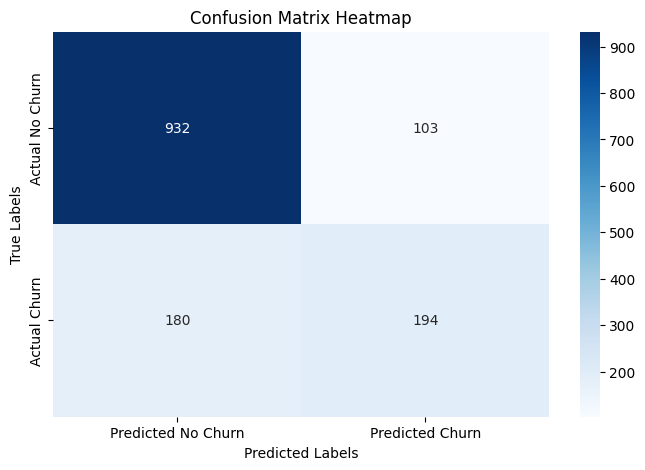

In [11]:
# Evaluation Metrics
from sklearn.metrics import classification_report

print(f"Classification Report")
print(classification_report(y_test,y_pred,target_names=["No Churn","Churn"]))

conf_matrix = confusion_matrix(y_test,y_pred)

plt.figure(figsize=(8,5))
sns.heatmap(conf_matrix,annot=True,fmt='g',cmap='Blues',cbar=True,
            xticklabels=['Predicted No Churn','Predicted Churn'],
            yticklabels=['Actual No Churn','Actual Churn'])

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

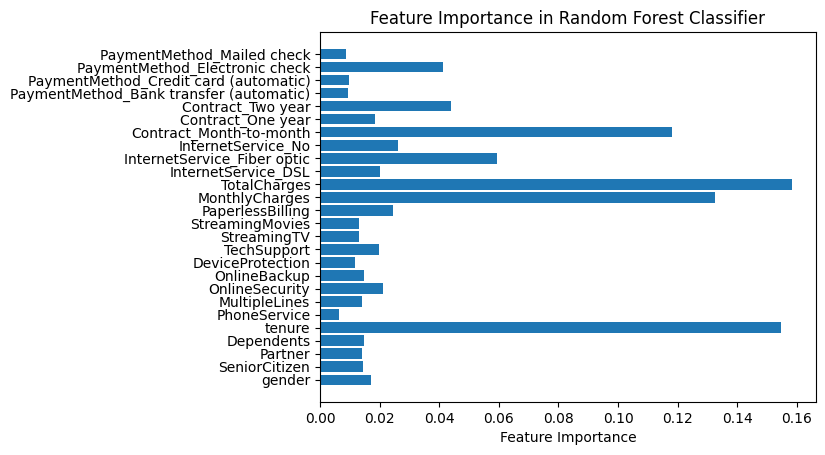

In [12]:
# Random Forest - Fetaure Importance

feature_import = classifier.feature_importances_

plt.barh(x_train.columns,feature_import)
plt.xlabel('Feature Importance')
plt.title('Feature Importance in Random Forest Classifier')
plt.show()

Hyperparameter Tuning - GridSearchCV

In [14]:
from sklearn.model_selection import GridSearchCV

params_grid = {
    'n_estimators' : [100,200],
    'max_depth' : [None,10,20],
    'min_samples_split' : [2,5],
    'min_samples_leaf' : [1,2],
    'bootstrap' : [True,False]
}

grid_search = GridSearchCV(RandomForestClassifier(),param_grid=params_grid)
grid_search.fit(x_train,y_train)

print(f"Best Parameter : ",grid_search.best_params_)
print(f"Best Estimator : ",grid_search.best_estimator_)

Best Parameter :  {'bootstrap': True, 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best Estimator :  RandomForestClassifier(max_depth=10, min_samples_leaf=2, min_samples_split=5,
                       n_estimators=200)


In [15]:
classifier = RandomForestClassifier(n_estimators = 200,max_depth=10,min_samples_leaf=2,min_samples_split=5,random_state=42)
classifier.fit(x_train,y_train)

y_pred = classifier.predict(x_test)
print(f"Accuracy of Random Forest Classifier {accuracy_score(y_test,y_pred)}")

print(f"Classification Report")
print(classification_report(y_test,y_pred,target_names=["No Churn","Churn"]))

Accuracy of Random Forest Classifier 0.8019872249822569
Classification Report
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.65      0.54      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



Hyperparameter Tuning - RandomsizedCV

In [18]:
from sklearn.model_selection import RandomizedSearchCV

random_Search = RandomizedSearchCV(RandomForestClassifier(),params_grid)
random_Search.fit(x_train,y_train)

print(f"Best Estimator : ",random_Search.best_estimator_)

Best Estimator :  RandomForestClassifier(bootstrap=False, max_depth=10, min_samples_leaf=2,
                       min_samples_split=5, n_estimators=200)


In [20]:
model_random = RandomForestClassifier(bootstrap=False,max_depth=10,min_samples_leaf=2,min_samples_split=5,n_estimators=200)

model_random.fit(x_train,y_train)

y_pred = model_random.predict(x_test)

print(f"Classification Report : \n",classification_report(y_pred,y_test))


Classification Report : 
               precision    recall  f1-score   support

           0       0.89      0.84      0.87      1100
           1       0.53      0.65      0.59       309

    accuracy                           0.80      1409
   macro avg       0.71      0.74      0.73      1409
weighted avg       0.82      0.80      0.81      1409

